# 04 · El camino: ¿cuánto se camina y desde dónde?

La prensa dice que la ruta Nogales-Magdalena mide 80, 85, 87.6, 88, 90 o 100 kilómetros. Aquí calculamos la distancia por carretera con OSRM (el motor de rutas de OpenStreetMap) desde cada cabecera de origen documentada y la comparamos con lo publicado.

**Limitación:** el servidor público de OSRM solo calcula rutas para vehículo. Los peregrinos usan acotamientos y veredas, así que la distancia real a pie puede variar unos kilómetros.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import plotly.graph_objects as go

from src import config, tema
from src import procesamiento as proc

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

In [2]:
rutas, geometrias = proc.leer_rutas()
rutas["horas_a_pie_4_5kmh"] = rutas["km_carretera"] / 4.5
rutas.round(1)

,mun,origen,km_carretera,horas_auto,origen_lat,origen_lon,horas_a_pie_4_5kmh
0,058,Santa Ana,18.7,0.4,30.5,-111.1,4.2
1,035,Ímuris,23.2,0.4,30.8,-110.9,5.2
2,022,Cucurpe,47.1,0.8,30.3,-110.7,10.5
3,043,Nogales,89.4,1.3,31.3,-110.9,19.9
4,019,Cananea,104.2,1.6,31.0,-110.3,23.2
5,002,Agua Prieta,187.9,2.9,31.3,-109.5,41.8


## 1. Lo que dice la prensa contra la carretera

In [3]:
distancias = proc.leer_distancias_prensa()
nogales = distancias[distancias["origen"] == "Nogales"].sort_values("km_min")
km_osrm_nogales = rutas.loc[rutas["origen"] == "Nogales", "km_carretera"].iloc[0]
nogales.assign(diferencia_vs_osrm=lambda d: (d["km_min"] - km_osrm_nogales).round(1))[["fecha_publicacion", "medio", "km_min", "diferencia_vs_osrm", "nota"]]

,fecha_publicacion,medio,km_min,diferencia_vs_osrm,nota
1,2024-10-04,El Imparcial,80.0,-9.4,"""Más de 80 km"""
9,2025-09-30,Meganoticias,80.0,-9.4,"""La travesía abarca 80 kilómetros"""
3,2025-09-24,El Imparcial,85.0,-4.4,Ruta de 85 km citada en el operativo de Nogale...
5,2026-09-25,El Imparcial,85.0,-4.4,Misma semana que D05 y otra cifra
0,2022-10-02,El Diario de Sonora,87.6,-1.8,Cifra puntual más repetida para la ruta
4,2026-09-22,El Diario de Sonora,88.0,-1.4,"""El trayecto de 88 kilómetros"""
2,2024-10-02,Nuevo Día,90.0,0.6,"""Más de 90 kilómetros"""
6,NaT,Fondazione Padre Kino,100.0,10.6,Solo titular (error SSL)


In [4]:
print(f"OSRM Nogales-Magdalena: {km_osrm_nogales:.1f} km")
print(f"Prensa: de {nogales['km_min'].min():.0f} a {nogales['km_min'].max():.0f} km ({nogales['km_min'].nunique()} cifras distintas en {len(nogales)} notas)")

OSRM Nogales-Magdalena: 89.4 km
Prensa: de 80 a 100 km (6 cifras distintas en 8 notas)


La cifra más citada (87.6 km) y la de 2026 (88 km) quedan a menos de 2 km de la ruta por carretera. Las de 80 y 100 km son redondeos.

El brief original hablaba de **50 a 76 km**. Ninguna ruta de origen cae ahí: Santa Ana e Ímuris quedan muy por debajo, Nogales y Cananea por encima. El rango más parecido es el de una crónica de 2014 sobre los **tohono o'odham**, que caminan "entre 50 y 90 km en cinco días" porque muchos se integran a la ruta en tramos.

Interactiva: outputs/figuras/04_distancias_nogales.html


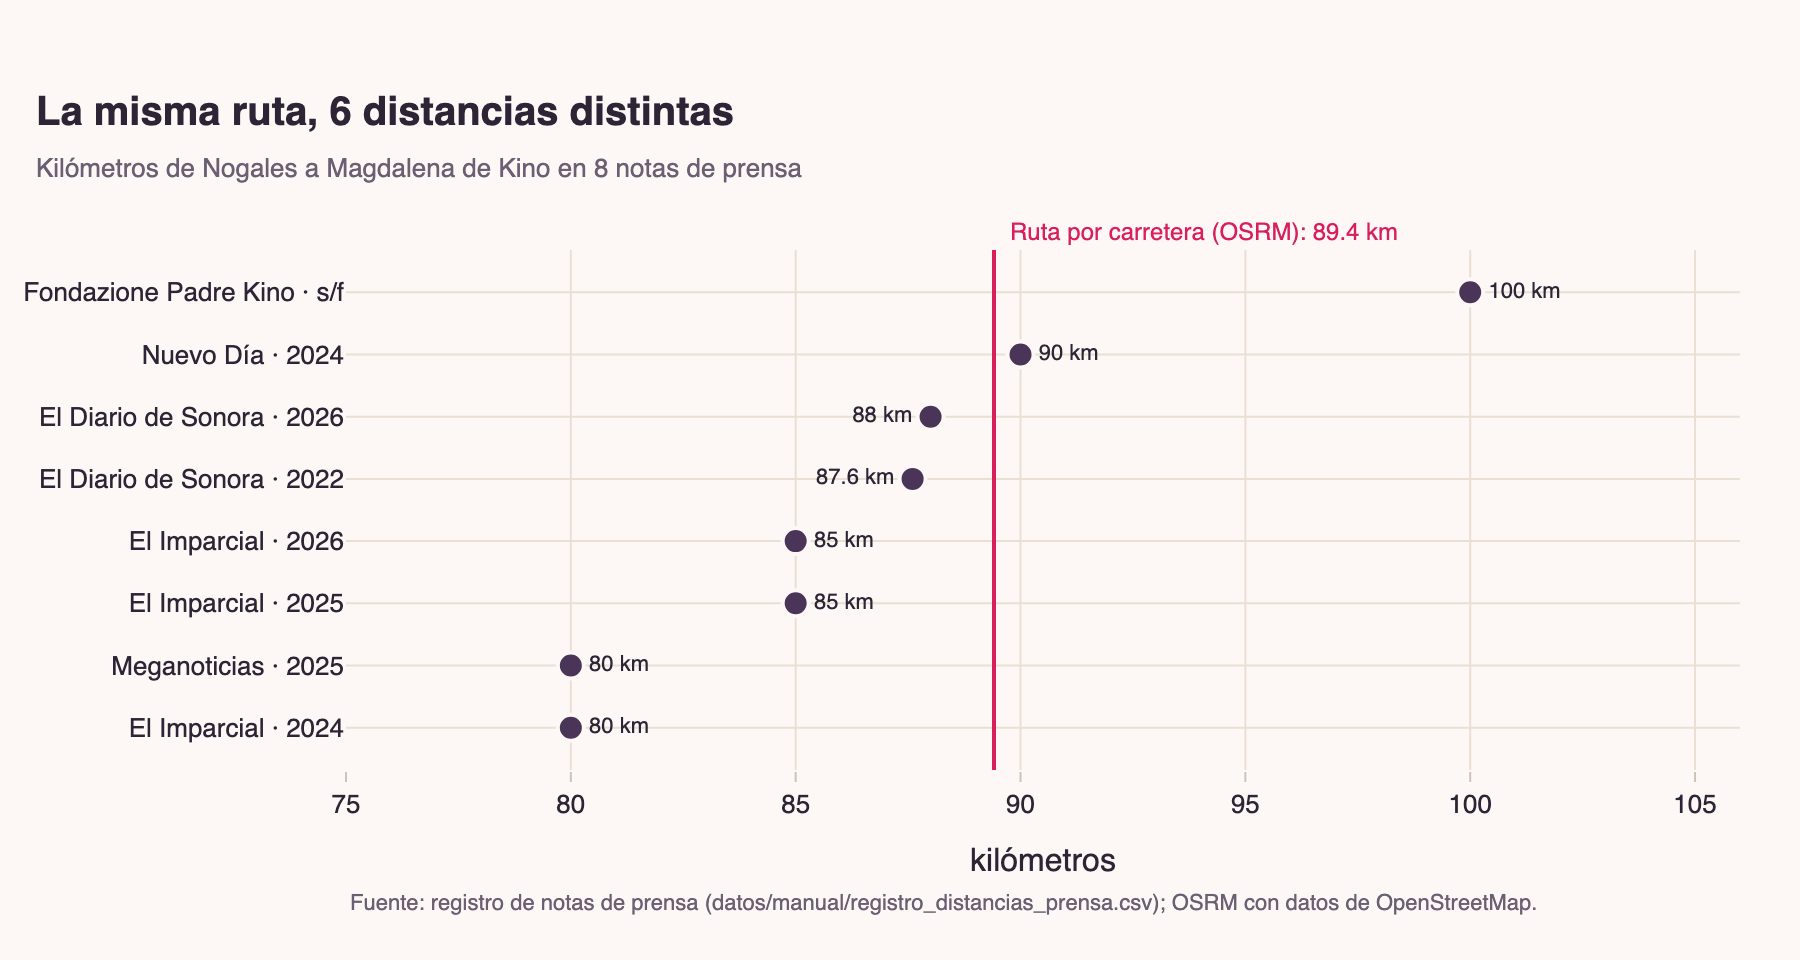

In [5]:
fig = go.Figure()
fig.add_vline(x=km_osrm_nogales, line=dict(color=tema.PROTAGONISTA, width=2))
fig.add_annotation(x=km_osrm_nogales, y=1.0, yref="paper", text=f"Ruta por carretera (OSRM): {km_osrm_nogales:.1f} km",
                   showarrow=False, xanchor="left", xshift=6, yanchor="bottom", font=dict(color=tema.PROTAGONISTA, size=12))
etiquetas = nogales["medio"] + " · " + nogales["fecha_publicacion"].dt.strftime("%Y").fillna("s/f")
fig.add_trace(go.Scatter(
    x=nogales["km_min"], y=etiquetas, mode="markers+text",
    marker=dict(size=13, color=tema.CONTORNO, line=dict(color=tema.FONDO, width=2)),
    text=[f"{v:g} km" for v in nogales["km_min"]],
    textposition=["middle left" if 86 < v < km_osrm_nogales else "middle right" for v in nogales["km_min"]], textfont=dict(size=11, color=tema.TEXTO),
    hovertemplate="%{y}<br><b>%{x} km</b><extra></extra>", showlegend=False,
))
fig.update_layout(
    title=tema.titulo(f"La misma ruta, {nogales['km_min'].nunique()} distancias distintas", f"Kilómetros de Nogales a Magdalena de Kino en {len(nogales)} notas de prensa"),
    xaxis=dict(range=[75, 106], title="kilómetros", showgrid=True, gridcolor=tema.CUADRICULA),
    yaxis=dict(categoryorder="array", categoryarray=list(etiquetas)),
    height=480,
)
tema.nota_fuente(fig, "Fuente: registro de notas de prensa (datos/manual/registro_distancias_prensa.csv); OSRM con datos de OpenStreetMap.")
tema.mostrar(fig, "04_distancias_nogales")

## 2. Mapa de rutas convergentes

Magdalena funciona como el centro de una red: Nogales es el eje principal, y Ímuris, Santa Ana, Cucurpe y Cananea son corredores con puntos de hidratación de Protección Civil. Agua Prieta aparece en la prensa como origen, pero no hay evidencia de que se camine completa.

Interactiva: outputs/figuras/05_mapa_rutas.html


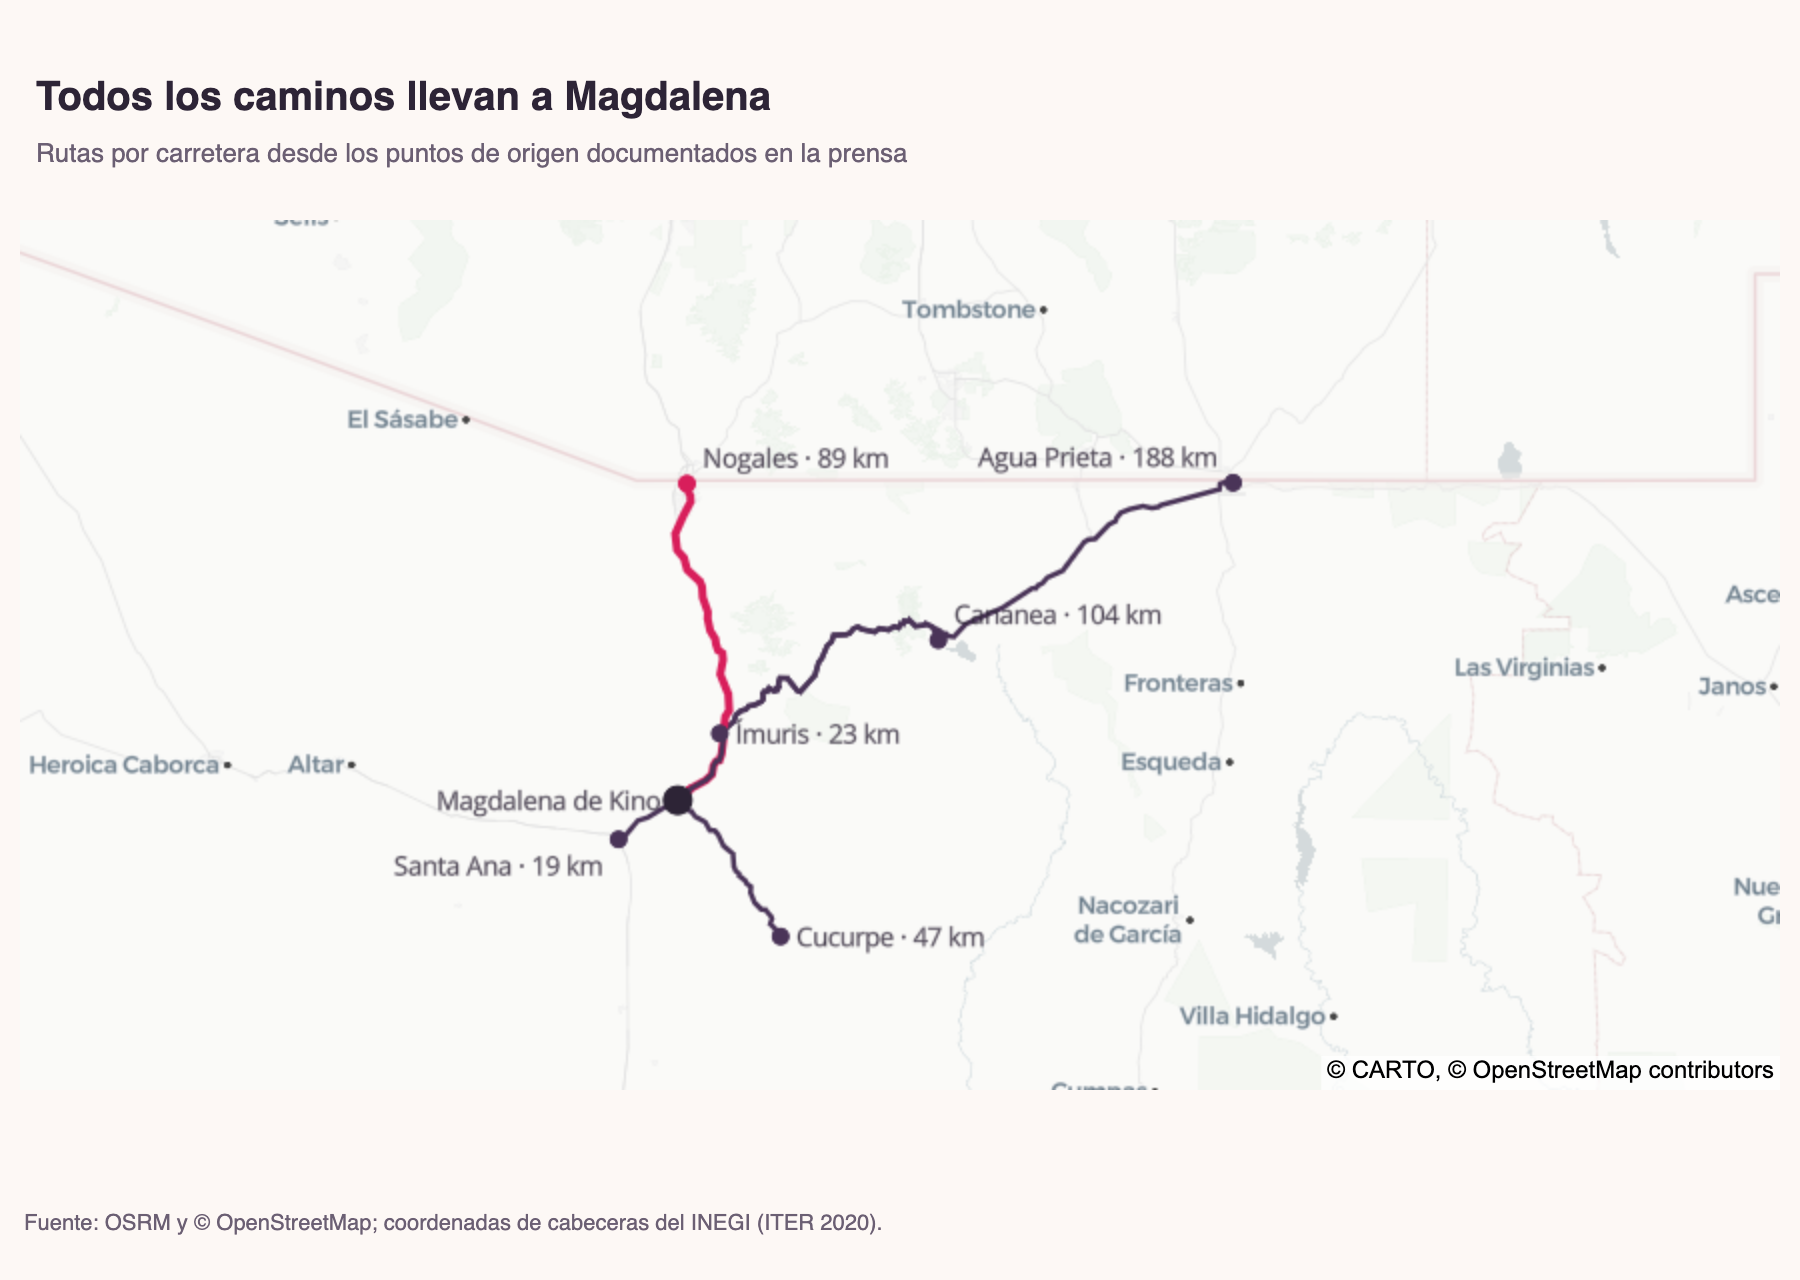

In [6]:
mag = proc.leer_iter(2020).query("mun == @config.CVE_MUN_MAGDALENA and loc == @config.CVE_LOC_CABECERA").iloc[0]
fig = go.Figure()
for _, r in rutas.sort_values("km_carretera", ascending=False).iterrows():
    coords = geometrias[r["mun"]]
    es_nogales = r["origen"] == "Nogales"
    fig.add_trace(go.Scattermap(
        lon=[c[0] for c in coords], lat=[c[1] for c in coords], mode="lines",
        line=dict(width=4 if es_nogales else 2.5, color=tema.PROTAGONISTA if es_nogales else tema.CONTORNO),
        name=r["origen"], hoverinfo="skip", showlegend=False,
    ))
POSICION = {"Santa Ana": "bottom left", "Ímuris": "middle right", "Cucurpe": "middle right", "Agua Prieta": "top left"}
for _, r in rutas.iterrows():
    color = tema.PROTAGONISTA if r["origen"] == "Nogales" else tema.CONTORNO
    fig.add_trace(go.Scattermap(
        lon=[r["origen_lon"]], lat=[r["origen_lat"]], mode="markers+text",
        marker=dict(size=10, color=color), text=[f"{r['origen']} · {r['km_carretera']:.0f} km"],
        textposition=POSICION.get(r["origen"], "top right"), textfont=dict(size=13, color=tema.TEXTO),
        hovertemplate="<b>%{text}</b> por carretera<extra></extra>", showlegend=False,
    ))
fig.add_trace(go.Scattermap(
    lon=[mag["lon"]], lat=[mag["lat"]], mode="markers+text",
    marker=dict(size=16, color=tema.TEXTO), text=["Magdalena de Kino"], textposition="middle left",
    textfont=dict(size=13, color=tema.TEXTO), hoverinfo="text", showlegend=False,
))
fig.update_layout(
    title=tema.titulo("Todos los caminos llevan a Magdalena", "Rutas por carretera desde los puntos de origen documentados en la prensa"),
    map=dict(style="carto-positron", center=dict(lat=30.95, lon=-110.4), zoom=7.1),
    height=640, margin=dict(l=10, r=10, t=110, b=95),
)
tema.nota_fuente(fig, "Fuente: OSRM y © OpenStreetMap; coordenadas de cabeceras del INEGI (ITER 2020).")
tema.mostrar(fig, "05_mapa_rutas", alto=640)

## 3. Kilómetros-persona: dimensionar el esfuerzo

Si tomamos las estimaciones de caminantes desde Nogales y suponemos que todos hacen la ruta completa, ¿cuánto suman? Es un **techo**, no una medición: muchos se integran en Ímuris o en tramos intermedios.

In [7]:
CIRCUNFERENCIA_TIERRA_KM = 40_075
caminantes = {"2026, más de 25 mil en carretera (29 sept)": 25000, "2026, proyección alta (Nogales)": 36000}
esfuerzo = pd.DataFrame([
    {"escenario": k, "caminantes": v, "km_persona": v * km_osrm_nogales,
     "vueltas_a_la_tierra": v * km_osrm_nogales / CIRCUNFERENCIA_TIERRA_KM}
    for k, v in caminantes.items()
])
esfuerzo.round(1)

,escenario,caminantes,km_persona,vueltas_a_la_tierra
0,"2026, más de 25 mil en carretera (29 sept)",25000,2235257.5,55.8
1,"2026, proyección alta (Nogales)",36000,3218770.8,80.3


## Conclusiones

- Nogales-Magdalena: **89.4 km por carretera**; la prensa publica siete cifras distintas, de 80 a 100 km.
- Las demás rutas: Santa Ana 18.7 km, Ímuris 23.2, Cucurpe 47.1, Cananea 104.2 y Agua Prieta 187.9.
- El rango de 50-76 km no corresponde a ninguna ruta; se parece al de los tohono o'odham (50-90 km).
- Con 25,000 caminantes haciendo la ruta completa, serían unos 2.2 millones de km: más de 55 vueltas a la Tierra (techo).

In [8]:
rutas.to_csv(config.DIR_PROCESSED / "rutas_osrm.csv", index=False)
esfuerzo.to_csv(config.DIR_PROCESSED / "km_persona.csv", index=False)